# RQ4 — Cross-project evaluation

Input: `../metrics/evaluation_macro_f1.csv` (project-level Macro-F1 of the six approaches on 30 repositories; also located when run from the repository root).

Outputs (displayed inline; no files are written): descriptive statistics, normality and omnibus tests, Holm-corrected pairwise comparisons, a compact summary table, and a pairwise effect-size heatmap.

Run: *Run All*.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

try:
    import pingouin as pg
except ImportError as exc:
    raise ImportError(
        "This notebook requires 'pingouin'. Install the "
        "dependencies before executing the analysis (pip install -r requirements.txt)."
    ) from exc

DATA_FILENAME = "evaluation_macro_f1.csv"
EXPECTED_PROJECTS = 30
EXPECTED_APPROACH_COLUMNS = [
    "svm",
    "codebert",
    "bilstm",
    "gpt-oss",
    "flaccs",
    "hqcm",
]

DISPLAY_LABELS = {
    "svm": "TF-IDF + Linear SVM",
    "codebert": "CodeBERT",
    "bilstm": "BiLSTM",
    "gpt-oss": "GPT-OSS 20B",
    "flaccs": "FLACCS",
    "hqcm": "CodeFuse HQCM",
}


def locate_evaluation_file(filename=DATA_FILENAME):
    """Locate the frozen evaluation input from either the notebook folder or repo root."""
    cwd = Path.cwd().resolve()
    candidates = [
        cwd / ".." / "metrics" / filename,
        cwd / "metrics" / filename,
        cwd / "results" / "rq4_1" / "cross_project" / "metrics" / filename,
    ]

    for parent in (cwd, *cwd.parents):
        candidates.append(
            parent / "results" / "rq4_1" / "cross_project" / "metrics" / filename
        )

    seen = set()
    for candidate in candidates:
        candidate = candidate.resolve()
        if candidate in seen:
            continue
        seen.add(candidate)
        if candidate.is_file():
            return candidate

    checked = "\n".join(f"  - {path}" for path in seen)
    raise FileNotFoundError(
        f"Could not locate {filename}. Checked:\n{checked}"
    )


DATA_PATH = locate_evaluation_file()

# The CSV is a machine-readable file: comma separator and decimal point.
df_raw = pd.read_csv(DATA_PATH)
df_raw.columns = df_raw.columns.str.strip()

expected_columns = ["project", *EXPECTED_APPROACH_COLUMNS]
missing_columns = [c for c in expected_columns if c not in df_raw.columns]
extra_columns = [c for c in df_raw.columns if c not in expected_columns]
if missing_columns or extra_columns:
    raise ValueError(
        "Unexpected evaluation schema. "
        f"Missing={missing_columns}; extra={extra_columns}."
    )

if len(df_raw) != EXPECTED_PROJECTS:
    raise ValueError(
        f"Expected {EXPECTED_PROJECTS} projects, found {len(df_raw)}."
    )

if df_raw["project"].isna().any() or (df_raw["project"].astype(str).str.strip() == "").any():
    raise ValueError("Project identifiers must be non-empty.")

if df_raw["project"].duplicated().any():
    duplicates = df_raw.loc[df_raw["project"].duplicated(), "project"].astype(str).tolist()
    raise ValueError(f"Duplicate project identifiers were found: {duplicates}")

for column in EXPECTED_APPROACH_COLUMNS:
    df_raw[column] = pd.to_numeric(df_raw[column], errors="raise")

if df_raw[EXPECTED_APPROACH_COLUMNS].isna().any().any():
    raise ValueError(
        "The cross-project evaluation must contain complete paired scores for all 30 projects."
    )

invalid_mask = (
    (df_raw[EXPECTED_APPROACH_COLUMNS] < 0)
    | (df_raw[EXPECTED_APPROACH_COLUMNS] > 1)
)
if invalid_mask.any().any():
    raise ValueError("Evaluation Macro-F1 values must lie in the [0, 1] interval.")

# Keep the frozen model order from the evaluation definition.
df_clean = (
    df_raw.set_index("project")[EXPECTED_APPROACH_COLUMNS]
    .rename(columns=DISPLAY_LABELS)
    .copy()
)

print(f"Evaluation file: {DATA_PATH}")
print(f"Paired projects: {len(df_clean)}")
print(f"Approaches ({len(df_clean.columns)}): {df_clean.columns.tolist()}")
display(df_clean.head())


def _round_small(frame, decimals):
    """Round for display; nonzero values that round to 0 are shown as <0.001."""
    rounded = frame.round(decimals)
    out = rounded.astype(object)
    for column in frame.select_dtypes("number").columns:
        tiny = (frame[column] != 0) & (rounded[column] == 0)
        out.loc[tiny, column] = "<0.001"
    return out


Evaluation file: results\rq4_1\cross_project\metrics\evaluation_macro_f1.csv
Paired projects: 30
Approaches (6): ['TF-IDF + Linear SVM', 'CodeBERT', 'BiLSTM', 'GPT-OSS 20B', 'FLACCS', 'CodeFuse HQCM']


,TF-IDF + Linear SVM,CodeBERT,BiLSTM,GPT-OSS 20B,FLACCS,CodeFuse HQCM
project,,,,,,
angular,0.315395,0.251315,0.193445,0.366053,0.372317,0.186802
ant-design,0.295297,0.348137,0.365068,0.314512,0.265150,0.137943
biome,0.285277,0.367275,0.384822,0.530260,0.411125,0.109474
bun,0.429396,0.628799,0.521278,0.601270,0.528825,0.150308
clap,0.342548,0.411575,0.359981,0.575735,0.638040,0.221537


## Analysis functions

In [2]:
from itertools import combinations
from scipy.stats import friedmanchisquare, shapiro, t, ttest_rel


def _format_p_plain(p_value, digits=4):
    p_value = float(p_value)
    if p_value < 0.001:
        return "<.001"
    return f"{p_value:.{digits}f}".lstrip("0")


def _effect_magnitude(effect, route):
    value = abs(float(effect))

    if route == "parametric":
        if value < 0.2:
            return "Negligible"
        if value < 0.5:
            return "Small"
        if value < 0.8:
            return "Medium"
        return "Large"

    if value < 0.1:
        return "Negligible"
    if value < 0.3:
        return "Small"
    if value < 0.5:
        return "Medium"
    return "Large"


def _sphericity_values(result):
    """Support named and tuple-like Pingouin return objects."""
    names = ("spher", "W", "chi2", "dof", "pval")
    if all(hasattr(result, name) for name in names):
        return {name: getattr(result, name) for name in names}

    return dict(zip(names, result))


def _pingouin_value(row, *candidates):
    normalized = {
        str(column).lower().replace("-", "_"): column
        for column in row.index
    }
    for candidate in candidates:
        key = candidate.lower().replace("-", "_")
        if key in normalized:
            return row[normalized[key]]
    raise KeyError(
        f"None of these columns were found: {candidates}"
    )


def _descriptive_table(data):
    n = len(data)
    means = data.mean()
    standard_deviations = data.std(ddof=1)
    standard_errors = standard_deviations / np.sqrt(n)
    critical_t = t.ppf(0.975, df=n - 1)
    mean_ranks = data.rank(
        axis=1,
        method="average",
        ascending=False,
    ).mean()

    table = pd.DataFrame({
        "N": n,
        "Mean Macro-F1": means,
        "SD": standard_deviations,
        "CI95 Lower": means - critical_t * standard_errors,
        "CI95 Upper": means + critical_t * standard_errors,
        "Mean Rank": mean_ranks,
    })

    return table.sort_values(
        ["Mean Rank", "Mean Macro-F1"],
        ascending=[True, False],
    )


def _pairwise_tests(data, route, alpha):
    rows = []

    for model_a, model_b in combinations(data.columns, 2):
        values_a = data[model_a].to_numpy()
        values_b = data[model_b].to_numpy()

        if route == "parametric":
            statistic, p_value = ttest_rel(values_a, values_b)

            if np.allclose(values_a - values_b, 0):
                effect = 0.0
            else:
                effect = pg.compute_effsize(
                    values_a,
                    values_b,
                    paired=True,
                    eftype="hedges",
                )

            statistic_name = "t"
            effect_name = "Hedges' g"
        else:
            if np.allclose(values_a - values_b, 0):
                statistic = 0.0
                p_value = 1.0
                effect = 0.0
            else:
                wilcoxon = pg.wilcoxon(
                    values_a,
                    values_b,
                    alternative="two-sided",
                ).iloc[0]
                statistic = _pingouin_value(
                    wilcoxon,
                    "W_val",
                    "W-val",
                )
                p_value = _pingouin_value(
                    wilcoxon,
                    "p_val",
                    "p-val",
                )
                effect = _pingouin_value(wilcoxon, "RBC")

            statistic_name = "W"
            effect_name = "Rank-biserial correlation"

        rows.append({
            "A": model_a,
            "B": model_b,
            "Mean A": float(np.mean(values_a)),
            "Mean B": float(np.mean(values_b)),
            "Statistic name": statistic_name,
            "Statistic": float(statistic),
            "p_raw": float(p_value),
            "Effect name": effect_name,
            "Effect": float(effect),
        })

    pairwise = pd.DataFrame(rows)
    reject, corrected_p = pg.multicomp(
        pairwise["p_raw"].to_numpy(),
        alpha=alpha,
        method="holm",
    )
    pairwise["p_Holm"] = corrected_p
    pairwise["Significant"] = reject
    pairwise["Winner"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["A"],
        pairwise["B"],
    )
    pairwise["Loser"] = np.where(
        pairwise["Effect"] >= 0,
        pairwise["B"],
        pairwise["A"],
    )
    pairwise["Absolute effect"] = pairwise["Effect"].abs()
    pairwise["Effect magnitude"] = pairwise["Effect"].map(
        lambda value: _effect_magnitude(value, route)
    )

    return pairwise


def run_model_comparison(data, alpha=0.05):
    descriptive = _descriptive_table(data)

    shapiro_rows = []
    for model in data.columns:
        statistic, p_value = shapiro(data[model])
        shapiro_rows.append({
            "Model": model,
            "N": int(data[model].notna().sum()),
            "W": float(statistic),
            "p": float(p_value),
            "Normality not rejected": bool(p_value >= alpha),
        })

    shapiro_results = pd.DataFrame(shapiro_rows).set_index("Model")
    all_normal = bool(
        shapiro_results["Normality not rejected"].all()
    )
    route = "parametric" if all_normal else "non-parametric"

    n_projects = len(data)
    n_models = len(data.columns)
    sphericity = None

    if route == "parametric":
        long_data = (
            data.rename_axis("Project")
            .reset_index()
            .melt(
                id_vars="Project",
                var_name="Model",
                value_name="Macro-F1",
            )
        )

        sphericity = _sphericity_values(
            pg.sphericity(
                data=long_data,
                dv="Macro-F1",
                within="Model",
                subject="Project",
            )
        )

        anova = pg.rm_anova(
            data=long_data,
            dv="Macro-F1",
            within="Model",
            subject="Project",
            correction=True,
            detailed=True,
            effsize="ng2",
        )
        anova_row = anova.iloc[0]
        statistic = float(_pingouin_value(anova_row, "F"))
        p_uncorrected = float(
            _pingouin_value(anova_row, "p_unc", "p-unc")
        )
        epsilon = float(_pingouin_value(anova_row, "eps"))
        effect = float(_pingouin_value(anova_row, "ng2"))

        if float(sphericity["pval"]) < alpha:
            p_value = float(
                _pingouin_value(
                    anova_row,
                    "p_GG_corr",
                    "p-GG-corr",
                )
            )
            df1 = epsilon * (n_models - 1)
            df2 = epsilon * (n_models - 1) * (n_projects - 1)
            correction = "Greenhouse-Geisser"
        else:
            p_value = p_uncorrected
            df1 = n_models - 1
            df2 = (n_models - 1) * (n_projects - 1)
            correction = "None"

        omnibus = {
            "test": "Repeated-measures ANOVA",
            "statistic name": "F",
            "statistic": statistic,
            "df1": float(df1),
            "df2": float(df2),
            "p": p_value,
            "effect name": "eta_G_squared",
            "effect": effect,
            "epsilon": epsilon,
            "correction": correction,
            "significant": bool(p_value < alpha),
        }
    else:
        statistic, p_value = friedmanchisquare(
            *[data[column].to_numpy() for column in data.columns]
        )
        kendalls_w = statistic / (
            n_projects * (n_models - 1)
        )
        omnibus = {
            "test": "Friedman",
            "statistic name": "chi-square",
            "statistic": float(statistic),
            "df1": float(n_models - 1),
            "df2": np.nan,
            "p": float(p_value),
            "effect name": "Kendall's W",
            "effect": float(kendalls_w),
            "epsilon": np.nan,
            "correction": "Not applicable",
            "significant": bool(p_value < alpha),
        }

    if omnibus["significant"]:
        pairwise = _pairwise_tests(data, route, alpha)
        significant_pairwise = pairwise.loc[
            pairwise["Significant"]
        ].copy()
    else:
        pairwise = None
        significant_pairwise = None

    # The leading approach is defined by the primary performance metric.
    leader = descriptive["Mean Macro-F1"].idxmax()
    not_distinguishable = [leader]

    if pairwise is not None:
        for model in descriptive.index[1:]:
            comparison = pairwise.loc[
                (
                    (pairwise["A"] == leader)
                    & (pairwise["B"] == model)
                )
                | (
                    (pairwise["A"] == model)
                    & (pairwise["B"] == leader)
                )
            ]
            if len(comparison) != 1:
                raise ValueError(
                    "Missing or duplicated leader comparison for "
                    f"{model}."
                )
            if not bool(comparison.iloc[0]["Significant"]):
                not_distinguishable.append(model)

    summary = descriptive.copy()
    summary["Not distinguishable from leader"] = [
        model in not_distinguishable
        for model in summary.index
    ]

    print("DESCRIPTIVE APPROACH TABLE")
    display(_round_small(summary, {
        "Mean Macro-F1": 4,
        "SD": 4,
        "CI95 Lower": 4,
        "CI95 Upper": 4,
        "Mean Rank": 2,
    }))

    print("SHAPIRO-WILK TESTS")
    shapiro_display = shapiro_results.copy()
    shapiro_display["W"] = shapiro_display["W"].round(4)
    shapiro_display["p"] = shapiro_display["p"].map(
        _format_p_plain
    )
    display(shapiro_display)

    print(f"SELECTED ROUTE: {route}")
    display(pd.DataFrame([omnibus]))

    if pairwise is None:
        pass
    else:
        print(
            "SIGNIFICANT HOLM-CORRECTED PAIRWISE COMPARISONS "
            f"({len(significant_pairwise)} of {len(pairwise)})"
        )
        pairwise_display = significant_pairwise.copy()
        pairwise_display["p_raw"] = pairwise_display["p_raw"].map(
            _format_p_plain
        )
        pairwise_display["p_Holm"] = pairwise_display[
            "p_Holm"
        ].map(_format_p_plain)
        display(_round_small(pairwise_display, {
            "Mean A": 4,
            "Mean B": 4,
            "Statistic": 4,
            "Effect": 4,
        }))

    return {
        "data": data,
        "descriptive": descriptive,
        "summary": summary,
        "shapiro": shapiro_results,
        "route": route,
        "sphericity": sphericity,
        "omnibus": omnibus,
        "pairwise": pairwise,
        "significant_pairwise": significant_pairwise,
        "leader": leader,
        "not_distinguishable": not_distinguishable,
        "alpha": alpha,
    }


## Run the analysis

In [3]:
evaluation_analysis = run_model_comparison(df_clean)

if evaluation_analysis["sphericity"] is not None:
    print("MAUCHLY'S TEST OF SPHERICITY")
    display(_round_small(pd.DataFrame([{
        "Mauchly W": evaluation_analysis["sphericity"]["W"],
        "chi-square": evaluation_analysis["sphericity"]["chi2"],
        "df": evaluation_analysis["sphericity"]["dof"],
        "p": evaluation_analysis["sphericity"]["pval"],
    }]), 4))


DESCRIPTIVE APPROACH TABLE


,N,Mean Macro-F1,SD,CI95 Lower,CI95 Upper,Mean Rank,Not distinguishable from leader
GPT-OSS 20B,30,0.476,0.1058,0.4365,0.5155,1.7,True
CodeBERT,30,0.4046,0.0906,0.3707,0.4384,2.67,False
FLACCS,30,0.392,0.0894,0.3586,0.4253,3.03,False
BiLSTM,30,0.3769,0.0974,0.3405,0.4133,3.4,False
TF-IDF + Linear SVM,30,0.3388,0.0773,0.31,0.3677,4.2,False
CodeFuse HQCM,30,0.1759,0.0639,0.152,0.1998,6.0,False


SHAPIRO-WILK TESTS


,N,W,p,Normality not rejected
Model,,,,
TF-IDF + Linear SVM,30,0.9594,.2997,True
CodeBERT,30,0.9191,.0255,False
BiLSTM,30,0.9757,.7043,True
GPT-OSS 20B,30,0.9767,.7334,True
FLACCS,30,0.9714,.5772,True
CodeFuse HQCM,30,0.9801,.8282,True


SELECTED ROUTE: non-parametric


,test,statistic name,statistic,df1,df2,p,effect name,effect,epsilon,correction,significant
0,Friedman,chi-square,93.447619,5.0,NaN,1.266616e-18,Kendall's W,0.622984,NaN,Not applicable,True


SIGNIFICANT HOLM-CORRECTED PAIRWISE COMPARISONS (11 of 15)


,A,B,Mean A,Mean B,Statistic name,Statistic,p_raw,Effect name,Effect,p_Holm,Significant,Winner,Loser,Absolute effect,Effect magnitude
0,TF-IDF + Linear SVM,CodeBERT,0.3388,0.4046,W,26.0,<.001,Rank-biserial correlation,-0.8882,<.001,True,CodeBERT,TF-IDF + Linear SVM,0.888172,Large
2,TF-IDF + Linear SVM,GPT-OSS 20B,0.3388,0.476,W,7.0,<.001,Rank-biserial correlation,-0.9699,<.001,True,GPT-OSS 20B,TF-IDF + Linear SVM,0.969892,Large
3,TF-IDF + Linear SVM,FLACCS,0.3388,0.392,W,86.0,.0019,Rank-biserial correlation,-0.6301,.0093,True,FLACCS,TF-IDF + Linear SVM,0.630108,Large
4,TF-IDF + Linear SVM,CodeFuse HQCM,0.3388,0.1759,W,0.0,<.001,Rank-biserial correlation,1.0,<.001,True,TF-IDF + Linear SVM,CodeFuse HQCM,1.0,Large
6,CodeBERT,GPT-OSS 20B,0.4046,0.476,W,81.0,.0012,Rank-biserial correlation,-0.6516,.0074,True,GPT-OSS 20B,CodeBERT,0.651613,Large
8,CodeBERT,CodeFuse HQCM,0.4046,0.1759,W,0.0,<.001,Rank-biserial correlation,1.0,<.001,True,CodeBERT,CodeFuse HQCM,1.0,Large
9,BiLSTM,GPT-OSS 20B,0.3769,0.476,W,49.0,<.001,Rank-biserial correlation,-0.7892,<.001,True,GPT-OSS 20B,BiLSTM,0.789247,Large
11,BiLSTM,CodeFuse HQCM,0.3769,0.1759,W,0.0,<.001,Rank-biserial correlation,1.0,<.001,True,BiLSTM,CodeFuse HQCM,1.0,Large
12,GPT-OSS 20B,FLACCS,0.476,0.392,W,18.0,<.001,Rank-biserial correlation,0.9226,<.001,True,GPT-OSS 20B,FLACCS,0.922581,Large
13,GPT-OSS 20B,CodeFuse HQCM,0.476,0.1759,W,0.0,<.001,Rank-biserial correlation,1.0,<.001,True,GPT-OSS 20B,CodeFuse HQCM,1.0,Large


## Compact table

In [4]:
compact_table = (
    evaluation_analysis["summary"][[
        "Mean Macro-F1",
        "SD",
        "Mean Rank",
        "Not distinguishable from leader",
    ]]
    .sort_values("Mean Macro-F1", ascending=False)
    .copy()
)

display(_round_small(compact_table, {
    "Mean Macro-F1": 3,
    "SD": 3,
    "Mean Rank": 2,
}))


,Mean Macro-F1,SD,Mean Rank,Not distinguishable from leader
GPT-OSS 20B,0.476,0.106,1.7,True
CodeBERT,0.405,0.091,2.67,False
FLACCS,0.392,0.089,3.03,False
BiLSTM,0.377,0.097,3.4,False
TF-IDF + Linear SVM,0.339,0.077,4.2,False
CodeFuse HQCM,0.176,0.064,6.0,False


## Holm-corrected pairwise effect-size heatmap

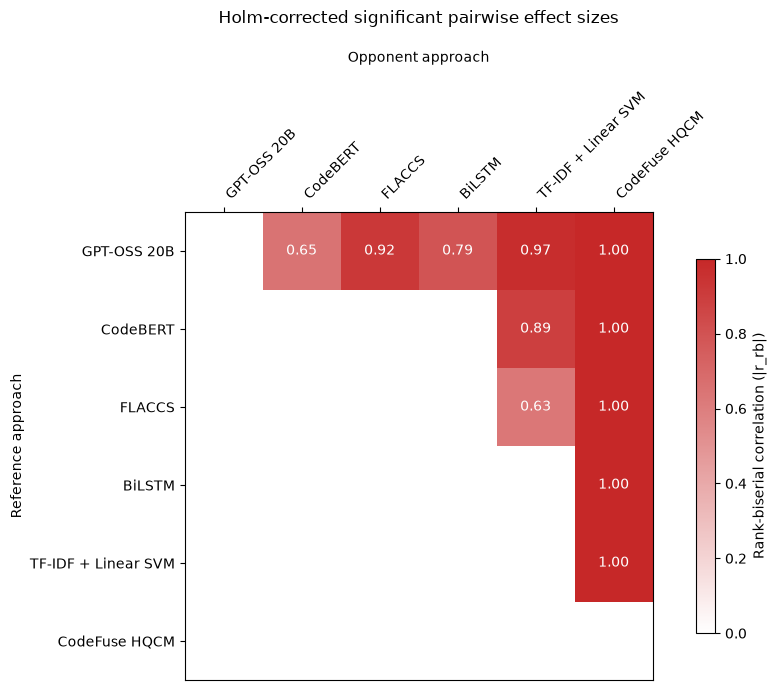

In [5]:
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

pairwise = evaluation_analysis["pairwise"]

if pairwise is None:
    pass
else:
    ordered_models = (
        evaluation_analysis["descriptive"]
        .sort_values("Mean Macro-F1", ascending=False)
        .index
        .tolist()
    )
    effect_matrix = pd.DataFrame(
        np.nan,
        index=ordered_models,
        columns=ordered_models,
    )
    p_matrix = effect_matrix.copy()

    for _, row in pairwise.iterrows():
        model_a = row["A"]
        model_b = row["B"]
        effect = float(row["Effect"])
        p_value = float(row["p_Holm"])

        effect_matrix.loc[model_a, model_b] = effect
        effect_matrix.loc[model_b, model_a] = -effect
        p_matrix.loc[model_a, model_b] = p_value
        p_matrix.loc[model_b, model_a] = p_value

    display_matrix = effect_matrix.to_numpy(dtype=float)
    mask = np.ones_like(display_matrix, dtype=bool)
    annotations = {}

    for i in range(len(ordered_models)):
        for j in range(i + 1, len(ordered_models)):
            p_value = p_matrix.iloc[i, j]
            if pd.notna(p_value) and p_value < evaluation_analysis["alpha"]:
                mask[i, j] = False
                annotations[(i, j)] = f"{effect_matrix.iloc[i, j]:.2f}"

    masked = np.ma.masked_where(mask, np.abs(display_matrix))
    effect_limit = (
        max(1.0, float(pairwise["Absolute effect"].max()))
        if evaluation_analysis["route"] == "parametric"
        else 1.0
    )

    fig, ax = plt.subplots(figsize=(10, 7))
    image = ax.imshow(
        masked,
        vmin=0,
        vmax=effect_limit,
        cmap=LinearSegmentedColormap.from_list("white_red", ["#ffffff", "#c62828"]),
        aspect="equal",
    )

    for (i, j), text in annotations.items():
        color = "white" if abs(display_matrix[i, j]) > 0.6 * effect_limit else "black"
        ax.text(j, i, text, ha="center", va="center", color=color)

    ax.set_xticks(range(len(ordered_models)))
    ax.set_yticks(range(len(ordered_models)))
    ax.set_xticklabels(ordered_models, rotation=45, ha="left")
    ax.set_yticklabels(ordered_models)
    ax.xaxis.tick_top()
    ax.set_xlabel("Opponent approach", labelpad=20)
    ax.xaxis.set_label_position("top")
    ax.set_ylabel("Reference approach")
    ax.set_title("Holm-corrected significant pairwise effect sizes", pad=20)

    effect_label = (
        "|Hedges' g|"
        if evaluation_analysis["route"] == "parametric"
        else "Rank-biserial correlation (|r_rb|)"
    )
    colorbar = fig.colorbar(image, ax=ax, shrink=0.8)
    colorbar.set_label(effect_label)

    fig.tight_layout()
    plt.show()
